In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import ccxt
from itertools import combinations
from statsmodels.tsa.stattools import coint

In [2]:
UNIVERSE = [
    "BTC",
    "ETH",
    "SOL",
    "BNB",
    "XRP",
    "DOGE",
    "ADA",
    "LINK",
    "AVAX",
    "DOT",
    "LTC",
    "ATOM",
    "AAVE",
    "UNI",
    "ARB",
    "OP",
    "SUI",
    "NEAR",
    "ALGO",
    "FIL"
]

In [3]:
SYMBOLS = [f"{coin}/USD" for coin in UNIVERSE]

In [4]:
exchange = ccxt.kraken()
markets = exchange.load_markets()

symbols = []

for coin in UNIVERSE:
    pair = f"{coin}/USD"
    if pair in markets:
        symbols.append(pair)

In [5]:
pairs = list(combinations(symbols, 2))

In [6]:
def to_df(data, symbol):
    df = pd.DataFrame(data, columns=["timestamp", "open", "high", "low", "close", "volume"])
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df[["timestamp", "close"]].copy()
    df = df.rename(columns={"close": symbol})
    return df

In [7]:
def align_pair_prices(prices, asset_a, asset_b):
    """
    prices: wide DataFrame with columns ['timestamp', asset_a, asset_b, ...]
    returns: DataFrame with only the two assets aligned and sorted
    """
    out = prices[["timestamp", asset_a, asset_b]].dropna().copy()
    out = out.sort_values("timestamp").reset_index(drop=True)
    return out

In [8]:
def estimate_ols_spread(df, asset_a, asset_b):
    """
    Regress log(asset_a) on log(asset_b).
    Returns:
        df_out with log prices, spread, residuals
        alpha, beta, corr, pvalue
    """
    out = df.copy()

    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])

    X = sm.add_constant(out[f"log_{asset_b}"])
    y = out[f"log_{asset_a}"]

    model = sm.OLS(y, X).fit()

    alpha = model.params["const"]
    beta = model.params[f"log_{asset_b}"]
    corr = out[[f"log_{asset_a}", f"log_{asset_b}"]].corr().iloc[0, 1]

    out["spread"] = model.resid
    return out, alpha, beta, corr, model.pvalues[f"log_{asset_b}"]

In [9]:
def spread_half_life(spread):
    """
    Estimate half-life from AR(1)-style mean reversion.
    """
    s = pd.Series(spread).dropna()
    lag = s.shift(1)
    diff = s - lag

    tmp = pd.concat([diff, lag], axis=1).dropna()
    tmp.columns = ["diff", "lag"]

    if len(tmp) < 5:
        return np.nan

    model = sm.OLS(tmp["diff"], sm.add_constant(tmp["lag"])).fit()
    lam = model.params["lag"]

    if lam >= 0:
        return np.nan

    return -np.log(2) / lam

In [10]:
def spread_crossings(z, threshold=2.0):
    """
    Count crossings of +/- threshold using one full-sample z-score series.
    """
    z = pd.Series(z).dropna()
    if len(z) < 2:
        return 0

    upper = ((z.shift(1) < threshold) & (z >= threshold)).sum()
    lower = ((z.shift(1) > -threshold) & (z <= -threshold)).sum()
    return int(upper + lower)

In [11]:
def pair_summary(prices, asset_a, asset_b, crossing_z=2.0):
    """
    One-row summary for pair selection.
    """
    df, alpha, beta, corr, pvalue = estimate_ols_spread(prices, asset_a, asset_b)

    spread = df["spread"].dropna()
    spread_vol = spread.std()
    hl = spread_half_life(spread)

    z = (spread - spread.mean()) / spread.std()
    crossings = spread_crossings(z, threshold=crossing_z)

    return pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Asset_A": asset_a,
        "Asset_B": asset_b,
        "Corr": corr,
        "P_value": pvalue,
        "Alpha": alpha,
        "Beta": beta,
        "Spread Vol": spread_vol,
        "Half_life": hl,
        "Z_score Crossings": crossings
    })

In [12]:
def rolling_zscore(series, window=25):
    mean = series.rolling(window).mean()
    std = series.rolling(window).std()
    return (series - mean) / std

In [13]:
def build_zscore_positions(z, entry_z=2.0, exit_z=0.25):
    """
    Stateful position series:
      +1 = long spread
      -1 = short spread
       0 = flat
    """
    position = 0
    positions = []

    for val in z:
        if pd.isna(val):
            positions.append(0)
            continue

        if position == 0:
            if val < -entry_z:
                position = 1
            elif val > entry_z:
                position = -1

        elif position == 1:
            if val > -exit_z:
                position = 0

        elif position == -1:
            if val < exit_z:
                position = 0

        positions.append(position)

    return pd.Series(positions, index=z.index)

In [14]:
def build_bollinger_positions(spread, window=25, band_k=1.0):
    """
    Stateful Bollinger-style spread strategy on the same spread.
    Enter on band break, exit when spread returns to rolling mean.
    """
    mid = spread.rolling(window).mean()
    std = spread.rolling(window).std()
    upper = mid + band_k * std
    lower = mid - band_k * std

    position = 0
    positions = []

    for s, m, u, l in zip(spread, mid, upper, lower):
        if pd.isna(s) or pd.isna(m) or pd.isna(u) or pd.isna(l):
            positions.append(0)
            continue

        if position == 0:
            if s < l:
                position = 1
            elif s > u:
                position = -1

        elif position == 1:
            if s >= m:
                position = 0

        elif position == -1:
            if s <= m:
                position = 0

        positions.append(position)

    out = pd.Series(positions, index=spread.index)
    return out, mid, upper, lower

In [15]:
def backtest_pair_strategy(
    prices,
    asset_a,
    asset_b,
    strategy="zscore",
    beta=None,
    window=25,
    entry_z=2.0,
    exit_z=0.25,
    band_k=1.0,
    fee_bps=0.0
):
    """
    prices: wide DataFrame with timestamp, asset_a, asset_b
    strategy: 'zscore' or 'bollinger'

    Returns:
        bt_df: full backtest DataFrame
        metrics: one-row summary Series
    """
    df = align_pair_prices(prices, asset_a, asset_b)
    df, alpha_hat, beta_hat, corr, pvalue = estimate_ols_spread(df, asset_a, asset_b)

    if beta is None:
        beta = beta_hat

    # Core spread
    df["spread"] = df["spread"]
    df["spread_mean"] = df["spread"].rolling(window).mean()
    df["spread_std"] = df["spread"].rolling(window).std()

    if strategy == "zscore":
        df["zscore"] = rolling_zscore(df["spread"], window=window)
        df["position"] = build_zscore_positions(
            df["zscore"], entry_z=entry_z, exit_z=exit_z
        )

    elif strategy == "bollinger":
        df["position"], df["bb_mid"], df["bb_upper"], df["bb_lower"] = build_bollinger_positions(
            df["spread"], window=window, band_k=band_k
        )

    else:
        raise ValueError("strategy must be 'zscore' or 'bollinger'")

    # Legs
    # position = +1 long spread => long A, short beta * B
    # position = -1 short spread => short A, long beta * B
    df["w_a"] = df["position"].astype(float)
    df["w_b"] = -beta * df["position"].astype(float)

    # Returns
    df[f"ret_{asset_a}"] = df[asset_a].pct_change()
    df[f"ret_{asset_b}"] = df[asset_b].pct_change()

    # Strategy return, shifted to avoid look-ahead
    raw_ret = (
        df["w_a"].shift(1) * df[f"ret_{asset_a}"] +
        df["w_b"].shift(1) * df[f"ret_{asset_b}"]
    )

    # Optional transaction costs on turnover
    turnover = (
        df["w_a"].diff().abs().fillna(0) +
        df["w_b"].diff().abs().fillna(0)
    )

    cost_per_turn = fee_bps / 10000.0
    costs = turnover * cost_per_turn

    df["strategy_ret"] = raw_ret - costs
    df["equity"] = (1 + df["strategy_ret"].fillna(0)).cumprod()

    # Metrics
    r = df["strategy_ret"].dropna()
    ann_factor = np.sqrt(24 * 365)

    sharpe = (r.mean() / r.std()) * ann_factor if r.std() != 0 else np.nan
    max_dd = (df["equity"] / df["equity"].cummax() - 1).min()
    cum_ret = df["equity"].iloc[-1] - 1
    trades = (df["position"].diff().fillna(0) != 0).sum()

    metrics = pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Strategy": strategy,
        "Corr": corr,
        "P-value": pvalue,
        "Alpha": alpha_hat,
        "Beta": beta,
        "Sharpe": sharpe,
        "Cumulative Return": cum_ret,
        "Max Drawdown": max_dd,
        "Trades": int(trades),
        "Mean Hourly Return": r.mean(),
        "Vol Hourly": r.std()
    })

    return df, metrics

In [16]:
prices = None

for coin in UNIVERSE:
    data = exchange.fetch_ohlcv(f"{coin}/USD", timeframe="1h", limit=1000)
    df = to_df(data, coin)

    if prices is None:
        prices = df
    else:
        prices = prices.merge(df, on="timestamp", how="inner")

In [19]:
candidate_rows = []

for a, b in pairs:
    candidate_rows.append(pair_summary(prices, a.split("/")[0], b.split("/")[0]))

pair_table = pd.DataFrame(candidate_rows).sort_values("P_value")

result = pair_table.query('Corr > 0.8')
result = result.query('P_value < 0.05')
result = result.sort_values(by="Half_life")
result = result.sort_values(by="Z_score Crossings", ascending=False)

selected_pairs = result.reset_index().drop(columns=["index"])

In [20]:
get_A = lambda x : x.split("/")[0]
get_B = lambda x : x.split("/")[1]

selected_pairs["Asset_A"] = selected_pairs["Pair"].apply(get_A)
selected_pairs["Asset_B"] = selected_pairs["Pair"].apply(get_B)

In [25]:
all_results = []
all_backtests = {}

for _, row in selected_pairs.iterrows():
    a = row["Asset_A"]
    b = row["Asset_B"]

    bt_z, m_z = backtest_pair_strategy(
        prices=prices,
        asset_a=a,
        asset_b=b,
        strategy="zscore",
        beta=row.get("Beta", None),
        window=25,
        entry_z=2.0,
        exit_z=0.25,
        fee_bps=0.0
    )

    bt_bb, m_bb = backtest_pair_strategy(
        prices=prices,
        asset_a=a,
        asset_b=b,
        strategy="bollinger",
        beta=row.get("Beta", None),
        window=25,
        band_k=1.0,
        fee_bps=0.0
    )

    all_backtests[(a, b, "zscore")] = bt_z
    all_backtests[(a, b, "bollinger")] = bt_bb

    all_results.append(m_z)
    all_results.append(m_bb)

results_df = pd.DataFrame(all_results).sort_values(["Pair", "Strategy"])
results_df = results_df.set_index(["Pair", "Strategy"]).sort_index()
results_df

Corr        P-value      Alpha      Beta    Sharpe  \
Pair     Strategy                                                            
ADA/LINK bollinger  0.834582  2.363976e-188  -5.127196  1.615656  0.105804   
         zscore     0.834582  2.363976e-188  -5.127196  1.615656  1.525070   
ADA/LTC  bollinger  0.818557  2.811905e-175 -10.095061  2.191372  4.064143   
         zscore     0.818557  2.811905e-175 -10.095061  2.191372  4.069671   
ADA/SUI  bollinger  0.825820  4.886834e-181  -1.347826  1.468467  1.508933   
...                      ...            ...        ...       ...       ...   
XRP/LTC  zscore     0.820453  9.346605e-177  -4.611802  1.248661  3.642584   
XRP/NEAR bollinger  0.928252   0.000000e+00  -0.262018  0.529217  7.491783   
         zscore     0.928252   0.000000e+00  -0.262018  0.529217  6.222979   
XRP/SUI  bollinger  0.838398  1.127348e-191   0.375879  0.847526  2.705067   
         zscore     0.838398  1.127348e-191   0.375879  0.847526  0.990482   

                    Cumulative Return  Max Drawdown  Trades  \
Pair     Strategy                                             
ADA/LINK bollinger          -0.006343     -0.174878      70   
         zscore              0.045737     -0.095699      46   
ADA/LTC  bollinger           0.246801     -0.153792      79   
         zscore              0.194126     -0.099689      43   
ADA/SUI  bollinger           0.061888     -0.153491      86   
...                               ...           ...     ...   
XRP/LTC  zscore              0.090311     -0.084685      49   
XRP/NEAR bollinger           0.228466     -0.060924      99   
         zscore              0.139340     -0.055875      53   
XRP/SUI  bollinger           0.075107     -0.092992      79   
         zscore              0.020261     -0.077214      49   

                    Mean Hourly Return  Vol Hourly  
Pair     Strategy                                   
ADA/LINK bollinger            0.000006    0.005484  
         zscore               0.000072    0.004409  
ADA/LTC  bollinger            0.000336    0.007745  
         zscore               0.000265    0.006093  
ADA/SUI  bollinger            0.000104    0.006478  
...                                ...         ...  
XRP/LTC  zscore               0.000125    0.003219  
XRP/NEAR bollinger            0.000292    0.003654  
         zscore               0.000185    0.002783  
XRP/SUI  bollinger            0.000107    0.003719  
         zscore               0.000033    0.003081  

[84 rows x 10 columns]

In [26]:
results_df.shape

(84, 10)

In [36]:
results_df.groupby("Strategy").mean(numeric_only=True)

,Corr,P-value,Alpha,Beta,Sharpe,Cumulative Return,Max Drawdown,Trades,Mean Hourly Return,Vol Hourly
Strategy,,,,,,,,,,
bollinger,0.875203,3.150151e-164,2.718316,0.888635,3.868871,0.110730,-0.086658,81.02381,0.000146,0.004120
zscore,0.875203,3.150151e-164,2.718316,0.888635,4.074791,0.087151,-0.069372,48.00000,0.000116,0.003302


In [ ]:
# interpret means
# Bollinger generated more trades, but also larger drawdowns, suggesting it reacts to smaller spread deviations. 
# Z-score produced fewer but higher-quality trades, leading to better risk-adjusted performance.

In [65]:
wide = results_df.unstack("Strategy")

In [66]:
comparison = wide[[
    ("Sharpe", "zscore"),
    ("Sharpe", "bollinger"),
    ("Cumulative Return", "zscore"),
    ("Cumulative Return", "bollinger"),
    ("Max Drawdown", "zscore"),
    ("Max Drawdown", "bollinger"),
]].copy()

comparison.columns = [
    "Sharpe_Z",
    "Sharpe_BB",
    "Return_Z",
    "Return_BB",
    "DD_Z",
    "DD_BB",
]
comparison["Sharpe_diff"] = comparison["Sharpe_Z"] - comparison["Sharpe_BB"]
comparison["Return_diff"] = comparison["Return_Z"] - comparison["Return_BB"]
comparison["DD_diff"] = comparison["DD_Z"] - comparison["DD_BB"]

In [67]:
comparison.head()

,Sharpe_Z,Sharpe_BB,Return_Z,Return_BB,DD_Z,DD_BB,Sharpe_diff,Return_diff,DD_diff
Pair,,,,,,,,,
ADA/LINK,1.525070,0.105804,0.045737,-0.006343,-0.095699,-0.174878,1.419267,0.052080,0.079179
ADA/LTC,4.069671,4.064143,0.194126,0.246801,-0.099689,-0.153792,0.005527,-0.052675,0.054103
ADA/SUI,3.356228,1.508933,0.140714,0.061888,-0.125825,-0.153491,1.847295,0.078826,0.027666
ATOM/ALGO,-0.473294,-0.922307,-0.048899,-0.089714,-0.169214,-0.223312,0.449014,0.040815,0.054098
ATOM/NEAR,1.348011,1.045913,0.050492,0.040694,-0.109101,-0.181235,0.302097,0.009798,0.072134


In [75]:
z_count = 0
b_count = 0

for _, row in comparison.iterrows():
    if row["Sharpe_diff"] > 0:
        z_count += 1
    else:
        b_count += 1


In [76]:
print(z_count > b_count)

True


In [40]:
bb_only = results_df.xs('bollinger', level='Strategy')
zscore = results_df.xs('zscore', level='Strategy')


In [77]:
zscore.head()

,Corr,P-value,Alpha,Beta,Sharpe,Cumulative Return,Max Drawdown,Trades,Mean Hourly Return,Vol Hourly
Pair,,,,,,,,,,
ADA/LINK,0.834582,2.363976e-188,-5.127196,1.615656,1.525070,0.045737,-0.095699,46,0.000072,0.004409
ADA/LTC,0.818557,2.811905e-175,-10.095061,2.191372,4.069671,0.194126,-0.099689,43,0.000265,0.006093
ADA/SUI,0.825820,4.886834e-181,-1.347826,1.468467,3.356228,0.140714,-0.125825,56,0.000198,0.005527
ATOM/ALGO,0.811457,6.834992e-170,4.032488,1.453996,-0.473294,-0.048899,-0.169214,45,-0.000039,0.007780
ATOM/NEAR,0.887331,6.542967e-244,-0.147979,0.951752,1.348011,0.050492,-0.109101,51,0.000086,0.005995


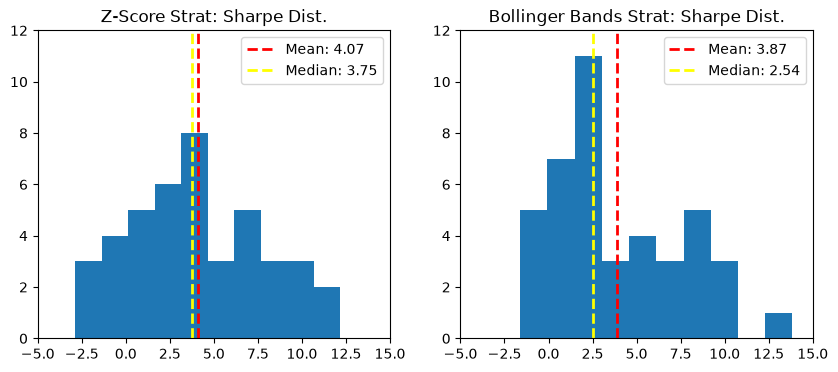

In [91]:
fig1, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].hist(zscore[["Sharpe"]])
zscore_mean = np.mean(zscore[["Sharpe"]])
ax[0].axvline(zscore_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {zscore_mean:.2f}')
zscore_median = np.median(zscore[["Sharpe"]])
ax[0].axvline(zscore_median, color='yellow', linestyle='dashed', linewidth=2, label=f'Median: {zscore_median:.2f}')

ax[1].hist(bb_only[["Sharpe"]])
bb_mean = np.mean(bb_only[["Sharpe"]])
ax[1].axvline(bb_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {bb_mean:.2f}')
bb_median = np.median(bb_only[["Sharpe"]])
ax[1].axvline(bb_median, color='yellow', linestyle='dashed', linewidth=2, label=f'Median: {bb_median:.2f}')

ax[0].set_title("Z-Score Strat: Sharpe Dist.")
ax[1].set_title("Bollinger Bands Strat: Sharpe Dist.")

ax[0].set_xlim(-5, 15)
ax[0].set_ylim(0, 12)
ax[1].set_xlim(-5, 15)
ax[1].set_ylim(0, 12)

ax[0].legend()
ax[1].legend()

In [100]:
results_df.index.get_level_values("Strategy").unique()

Index(['bollinger', 'zscore'], dtype='str', name='Strategy')

In [103]:
color_map = {'zscore': 'yellow', 'bollinger': 'red'}
colors = [color_map[cat] for cat in results_df.index.get_level_values("Strategy")]

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_80357/759719422.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Risk to Return Comparison')

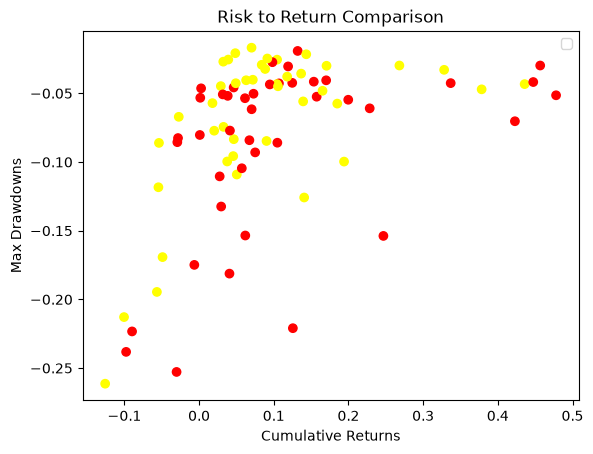

In [107]:
plt.scatter(results_df[["Cumulative Return"]].values, results_df[["Max Drawdown"]].values, c=colors)
plt.xlabel("Cumulative Returns")
plt.ylabel("Max Drawdowns")
plt.legend()
plt.title("Risk to Return Comparison")

Text(0.5, 0.98, 'Distribution of Metrics Differences')

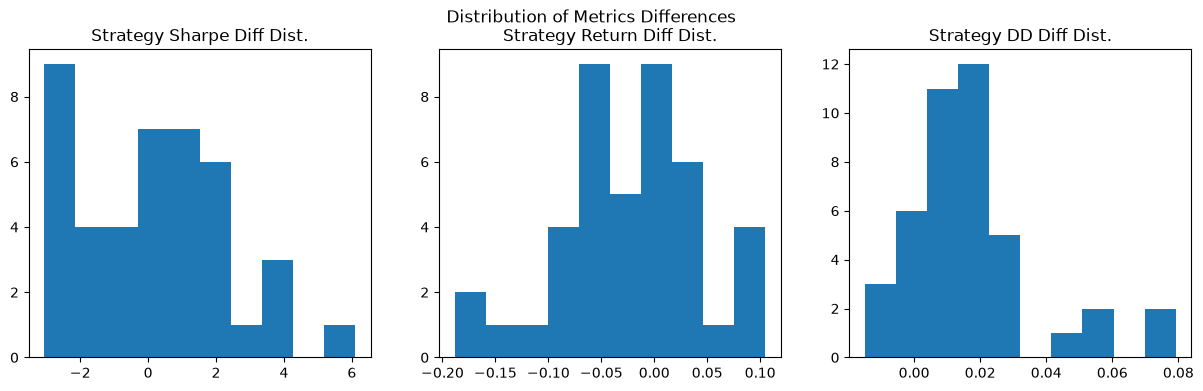

In [ ]:
fig3, ax3 = plt.subplots(1, 3, figsize=(15, 4))

ax3[0].hist(comparison[["Sharpe_diff"]])
ax3[1].hist(comparison[["Return_diff"]])
ax3[2].hist(comparison[["DD_diff"]])

ax3[0].set_title("Strategy Sharpe Diff Dist.")
ax3[1].set_title("Strategy Return Diff Dist.")
ax3[2].set_title("Strategy DD Diff Dist.")

fig3.suptitle("Distribution of Metrics Differences")

Text(0.5, 0.98, 'Performance Metrics Comparison')

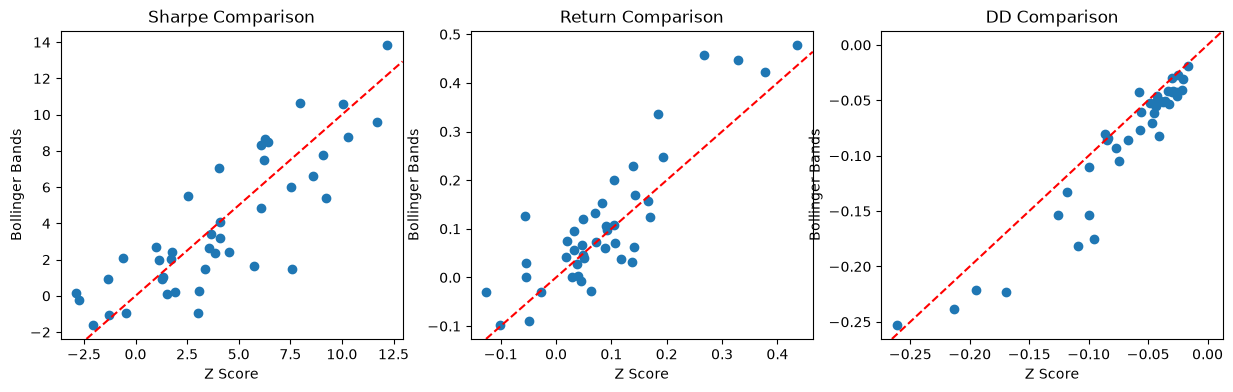

In [111]:
fig4, ax4 = plt.subplots(1, 3, figsize=(15, 4))

ax4[0].scatter(comparison[["Sharpe_Z"]], comparison[["Sharpe_BB"]])
ax4[1].scatter(comparison[["Return_Z"]], comparison[["Return_BB"]])
ax4[2].scatter(comparison[["DD_Z"]], comparison[["DD_BB"]])

ax4[0].set_title("Sharpe Comparison")
ax4[1].set_title("Return Comparison")
ax4[2].set_title("DD Comparison")

ax4[0].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")
ax4[1].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")
ax4[2].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")

ax4[0].set_xlabel("Z Score")
ax4[1].set_xlabel("Z Score")
ax4[2].set_xlabel("Z Score")

ax4[0].set_ylabel("Bollinger Bands")
ax4[1].set_ylabel("Bollinger Bands")
ax4[2].set_ylabel("Bollinger Bands")

fig3.suptitle("Performance Metrics Comparison")

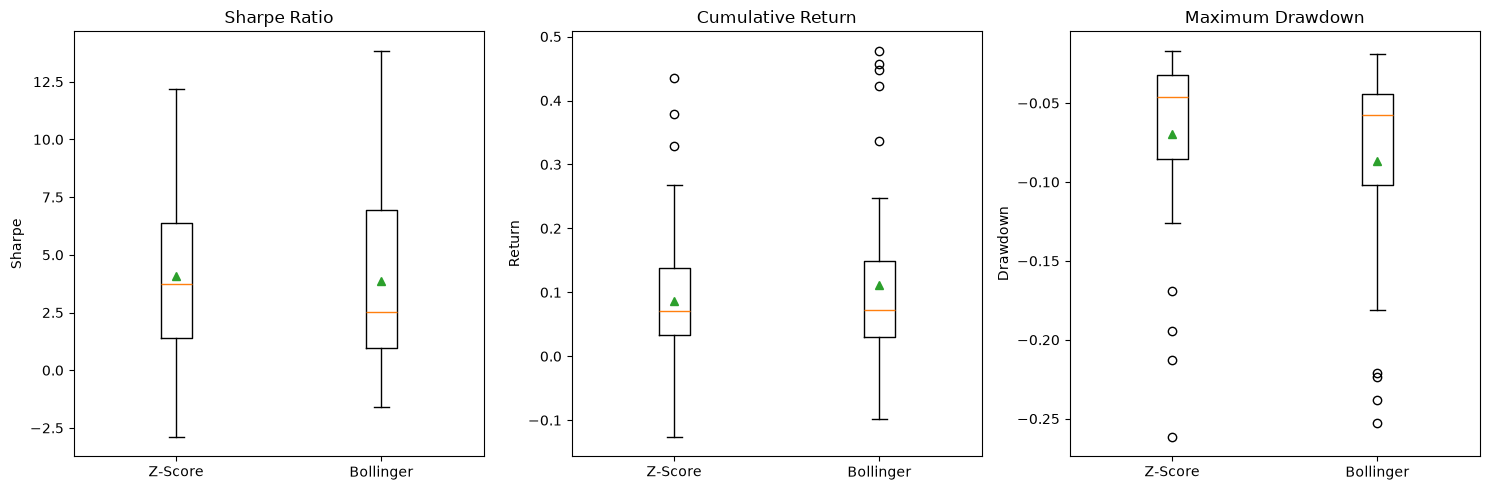

In [117]:
fig5, ax5 = plt.subplots(1, 3, figsize=(15, 5))

# -----------------------
# Sharpe
# -----------------------
ax5[0].boxplot(
    [comparison["Sharpe_Z"], comparison["Sharpe_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[0].set_title("Sharpe Ratio")
ax5[0].set_ylabel("Sharpe")

# -----------------------
# Cumulative Return
# -----------------------
ax5[1].boxplot(
    [comparison["Return_Z"], comparison["Return_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[1].set_title("Cumulative Return")
ax5[1].set_ylabel("Return")

# -----------------------
# Max Drawdown
# -----------------------
ax5[2].boxplot(
    [comparison["DD_Z"], comparison["DD_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[2].set_title("Maximum Drawdown")
ax5[2].set_ylabel("Drawdown")

plt.tight_layout()
plt.show()

In [118]:
comparison.head()

,Sharpe_Z,Sharpe_BB,Return_Z,Return_BB,DD_Z,DD_BB,Sharpe_diff,Return_diff,DD_diff
Pair,,,,,,,,,
ADA/LINK,1.525070,0.105804,0.045737,-0.006343,-0.095699,-0.174878,1.419267,0.052080,0.079179
ADA/LTC,4.069671,4.064143,0.194126,0.246801,-0.099689,-0.153792,0.005527,-0.052675,0.054103
ADA/SUI,3.356228,1.508933,0.140714,0.061888,-0.125825,-0.153491,1.847295,0.078826,0.027666
ATOM/ALGO,-0.473294,-0.922307,-0.048899,-0.089714,-0.169214,-0.223312,0.449014,0.040815,0.054098
ATOM/NEAR,1.348011,1.045913,0.050492,0.040694,-0.109101,-0.181235,0.302097,0.009798,0.072134


In [121]:
from scipy.stats import ttest_rel
ttest_rel(comparison["Sharpe_Z"], comparison["Sharpe_BB"])

TtestResult(statistic=np.float64(0.6035772609229567), pvalue=np.float64(0.549449695289082), df=np.int64(41))

In [122]:
ttest_rel(comparison["Return_Z"], comparison["Return_BB"])


TtestResult(statistic=np.float64(-2.2374270685473885), pvalue=np.float64(0.03075531823953462), df=np.int64(41))

In [123]:
ttest_rel(comparison["DD_Z"], comparison["DD_BB"])

TtestResult(statistic=np.float64(5.8228211511232155), pvalue=np.float64(7.728644338028824e-07), df=np.int64(41))

In [28]:
results_df.sort_values(by="Sharpe", ascending=False)

Corr        P-value      Alpha      Beta     Sharpe  \
Pair      Strategy                                                             
BTC/FIL   bollinger  0.886888  2.471530e-243  11.241706  0.761557  13.847175   
          zscore     0.886888  2.471530e-243  11.241706  0.761557  12.183516   
ETH/FIL   zscore     0.858831  4.594700e-211   7.728682  1.115539  11.694470   
LTC/FIL   bollinger  0.838655  6.692323e-192   3.955912  0.686954  10.668915   
LINK/FIL  bollinger  0.922655  9.160357e-300   2.320076  1.045132  10.590705   
...                       ...            ...        ...       ...        ...   
DOT/NEAR  zscore     0.936173   0.000000e+00  -0.689096  0.824946  -1.310603   
DOT/ALGO  bollinger  0.868617  1.822197e-221   2.978907  1.278667  -1.604944   
          zscore     0.868617  1.822197e-221   2.978907  1.278667  -2.040394   
DOGE/ALGO zscore     0.859084  2.529885e-211   0.369100  1.207638  -2.733761   
XRP/DOGE  zscore     0.837083  1.608171e-190   1.554073  0.567146  -2.875908   

                     Cumulative Return  Max Drawdown  Trades  \
Pair      Strategy                                             
BTC/FIL   bollinger           0.456746     -0.029757     101   
          zscore              0.268210     -0.029757      54   
ETH/FIL   zscore              0.435919     -0.043291      52   
LTC/FIL   bollinger           0.336909     -0.042575     101   
LINK/FIL  bollinger           0.447448     -0.041780     101   
...                                ...           ...     ...   
DOT/NEAR  zscore             -0.054420     -0.118371      47   
DOT/ALGO  bollinger          -0.097672     -0.238196      77   
          zscore             -0.100467     -0.212873      45   
DOGE/ALGO zscore             -0.125734     -0.261360      39   
XRP/DOGE  zscore             -0.053707     -0.086086      39   

                     Mean Hourly Return  Vol Hourly  
Pair      Strategy                                   
BTC/FIL   bollinger            0.000529    0.003576  
          zscore               0.000333    0.002561  
ETH/FIL   zscore               0.000511    0.004089  
LTC/FIL   bollinger            0.000410    0.003595  
LINK/FIL  bollinger            0.000524    0.004635  
...                                 ...         ...  
DOT/NEAR  zscore              -0.000066    0.004746  
DOT/ALGO  bollinger           -0.000119    0.006923  
          zscore              -0.000129    0.005933  
DOGE/ALGO zscore              -0.000170    0.005809  
XRP/DOGE  zscore              -0.000074    0.002401  

[84 rows x 10 columns]

In [29]:
results_df.sort_values(by="Cumulative Return", ascending=False)

,,Corr,P-value,Alpha,Beta,Sharpe,Cumulative Return,Max Drawdown,Trades,Mean Hourly Return,Vol Hourly
Pair,Strategy,,,,,,,,,,
ETH/FIL,bollinger,0.858831,4.594700e-211,7.728682,1.115539,9.612623,0.477995,-0.051417,99,0.000557,0.005428
BTC/FIL,bollinger,0.886888,2.471530e-243,11.241706,0.761557,13.847175,0.456746,-0.029757,101,0.000529,0.003576
LINK/FIL,bollinger,0.922655,9.160357e-300,2.320076,1.045132,10.590705,0.447448,-0.041780,101,0.000524,0.004635
ETH/FIL,zscore,0.858831,4.594700e-211,7.728682,1.115539,11.694470,0.435919,-0.043291,52,0.000511,0.004089
XRP/FIL,bollinger,0.846723,3.130867e-199,0.378997,1.055545,8.744279,0.422898,-0.070316,91,0.000505,0.005400
...,...,...,...,...,...,...,...,...,...,...,...
NEAR/ALGO,zscore,0.858326,1.505702e-210,4.165295,1.433876,-0.624416,-0.056463,-0.194561,43,-0.000051,0.007678
ATOM/ALGO,bollinger,0.811457,6.834992e-170,4.032488,1.453996,-0.922307,-0.089714,-0.223312,67,-0.000089,0.009073
DOT/ALGO,bollinger,0.868617,1.822197e-221,2.978907,1.278667,-1.604944,-0.097672,-0.238196,77,-0.000119,0.006923
